Lab01 — sprint 1

Тема: сравнение точности функционала r2SCAN и нейросетевой поправки к нему NN‑r2SCAN(Разработанного одним из членов команды для научной работы) на эталонной базе GSCDB137. Для чуть более подробного ознакомления навайбил презентацию о том как создавался метод, к сожалению нет большого количества времени, чтобы это описать самостоятельно с картинками и тд, это уже статья получиться (вы попросили меня описать ведь вам было интересно)(статья на которую я активно ссылаюсь:https://doi.org/10.1021/acs.jctc.6c00270)

Данные: для 861 химической реакции из 43 наборов GSCDB137 известны референсная энергия (эталон, «правильный ответ») и энергии, посчитанные двумя функционалами в одинаковых условиях (def2‑TZVPP, D3(BJ)). Все энергии в ккал/моль.
Данные были получены целиком нами 
P.S.Спасибо cHARISMa ВШЭ

Случайные величины:

1. $\varepsilon_\mathrm{r2}$ — ошибка r2SCAN на реакции;
2. $\varepsilon_\mathrm{NN}$ — ошибка NN‑r2SCAN на той же реакции (величина той же природы, поэтому проверяется зависимость);
3. $\Delta=|\varepsilon_\mathrm{NN}|-|\varepsilon_\mathrm{r2}|$ — выигрыш NN на реакции.


 Данные

In [38]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
COL = {"r2SCAN": "#2a78d6", "NN-r2SCAN": "#eb6834"}
TYPES = ["BH", "TC", "ISO", "INC", "NC"]   # барьеры, термохимия, изомеризация, внутри- и межмолекулярные взаимодействия

path = "gscdb_results/applied_def2-tzvpp_scf/analysis/"
info = json.load(open(path + "summary.json"))
df = pd.read_csv(path + "per_reaction.csv")
df.columns = ["reaction", "dataset", "ref", "E_r2", "E_nn", "e_r2", "e_nn"]
df["type"] = df.dataset.map({k: v["datatype"] for k, v in info["stats"].items()})
df["s_ref"] = df.dataset.map({k: v["standard_error"] for k, v in info["stats"].items()})  # погрешность эталона набора

# 30 реакций состоят из молекул, на которых обучалась нейросеть, — их убираем (иначе NN «знает ответ»)
print("реакций всего:", len(df))
df = df[~df.reaction.isin(info["training_overlap"])].reset_index(drop=True)
print("реакций после очистки:", len(df))
df.head()

реакций всего: 891
реакций после очистки: 861


,reaction,dataset,ref,E_r2,E_nn,e_r2,e_nn,type,s_ref
0,ACONF_1,ACONF,0.598000,0.673000,0.672058,0.075000,0.074058,INC,0.047325
1,ACONF_2,ACONF,0.614000,0.679027,0.678934,0.065027,0.064933,INC,0.047325
2,ACONF_3,ACONF,0.961001,1.056417,1.054587,0.095416,0.093586,INC,0.047325
3,ACONF_4,ACONF,2.813002,2.987282,2.998534,0.174280,0.185532,INC,0.047325
4,ACONF_5,ACONF,0.595001,0.652850,0.652772,0.057849,0.057772,INC,0.047325


Что лежит в колонках датасета

Каждая строка таблицы `df` — одна химическая реакция. Все энергии в ккал/моль.

| колонка | что в ней |
|---|---|
| `reaction` | имя реакции в GSCDB137: имя набора + номер, например `ACONF_1` |
| `dataset` | набор, к которому относится реакция (всего 43 набора: `S66`, `BH28`, `WCPT26`, …). Внутри одного набора реакции одного типа и с похожими молекулами |
| `ref` | эталонная энергия $E_\mathrm{ref}$ из GSCDB137 — результат высокоточных расчётов (в основном уровня CCSD(T)/CBS), «правильный ответ». Смотря по набору, это энергия реакции, высота барьера, энергия взаимодействия молекул или разность энергий конформеров/изомеров |
| `E_r2` | та же энергия, посчитанная функционалом r2SCAN (def2‑TZVPP, D3(BJ)) |
| `E_nn` | та же энергия, посчитанная NN‑r2SCAN (r2SCAN + нейросетевая поправка) в тех же условиях |
| `e_r2` | ошибка r2SCAN $\varepsilon_\mathrm{r2}=E_\mathrm{r2}-E_\mathrm{ref}$. Знак важен: $<0$ — функционал занижает энергию, $>0$ — завышает |
| `e_nn` | ошибка NN‑r2SCAN $\varepsilon_\mathrm{NN}=E_\mathrm{NN}-E_\mathrm{ref}$ |
| `type` | тип химии набора: **BH** — высоты барьеров реакций, **TC** — термохимия (энергии реакций, разрыва связей), **ISO** — энергии изомеризации, **INC** — внутримолекулярные нековалентные взаимодействия (конформеры), **NC** — межмолекулярные нековалентные взаимодействия (комплексы, водородные связи) |
| `s_ref` | погрешность эталона (standard error из GSCDB137). Одна на весь набор, от 0.05 до 1.93 ккал/моль |

Первые 7 колонок берутся из `per_reaction.csv` (там они называются `Reaction, Dataset, Reference, r2SCAN, r2SCAN+NN(...), err(r2SCAN), err(r2SCAN+NN(...))`, мы их просто переименовали). `type` и `s_ref` подтягиваются из `summary.json` по имени набора. Дальше по ходу работы появляются производные колонки: `u_r2`, `z_r2`, `w_r2` (нормализованные ошибки), `z_nn`, `delta` (выигрыш NN) и т.д.


Случайная величина 1 — ошибка r2SCAN $\varepsilon_\mathrm{r2}$ <a id="rv1"></a>
 
 
 Description (природа события)

Элементарное событие $\omega$ — химическая реакция. $\Omega$ — все реакции того типа химии, который покрывает GSCDB137, а наши 861 реакция — множество $A\subset\Omega$, которое удалось исследовать. Случайная величина:
$$\omega\ \mapsto\ \varepsilon_\mathrm{r2}(\omega)=E_\mathrm{r2SCAN}(\omega)-E_\mathrm{ref}(\omega).$$

Почему это случайная величина. Как и в примере с пингвинами, вся случайность сидит в выборе реакции $\omega$: когда реакция выбрана, расчёт DFT даёт определённое число. Но заранее, по виду реакции, ошибку предсказать нельзя:
 реакции одного и того же набора (одинаковый тип химии, похожие молекулы) имеют разные ошибки — разброс внутри набора показан ниже;
сам эталон $E_\mathrm{ref}$ известен с погрешностью $s_\mathrm{ref}$ (от 0.05 до 1.9 ккал/моль), поэтому даже «правильный ответ» содержит случайную составляющую.

Значит, формулы $\varepsilon=f(\text{реакция})$ нет, и ошибку разумно описывать как случайную величину.

разброс ошибки внутри наборов (ккал/моль):


,count,mean,std,min,max
dataset,,,,,
ADIM6,4,-0.146837,0.044364,-0.193535,-0.091502
ACONF,15,0.138816,0.068347,0.057849,0.299989
RSE43,30,-1.566822,0.813178,-4.296662,-0.651757
CARBHB8,8,0.954445,0.912708,0.037735,2.921598
WCPT26,26,-8.815878,4.506739,-18.890740,-1.953205
BDE99nonMR,17,-0.198065,5.629545,-10.504203,8.144479


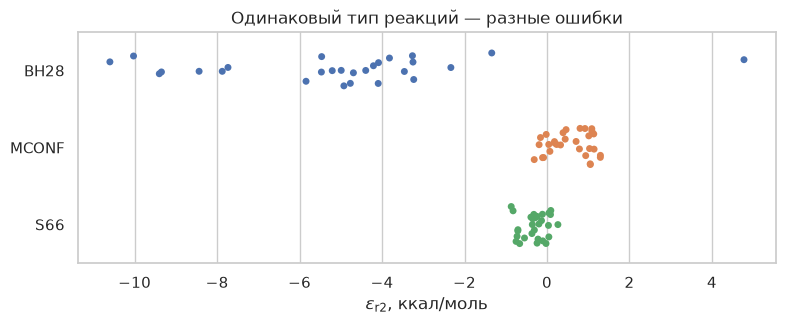

In [39]:
spread = df.groupby("dataset").e_r2.agg(["count", "mean", "std", "min", "max"]).sort_values("std")
print("разброс ошибки внутри наборов (ккал/моль):")
display(spread.iloc[[0, 1, 20, 21, -2, -1]])

fig, ax = plt.subplots(figsize=(9, 3))
ex = df[df.dataset.isin(["S66", "MCONF", "BH28"])]
sns.stripplot(data=ex, x="e_r2", y="dataset", hue="dataset", jitter=0.25, size=5, ax=ax, legend=False)
ax.set_xlabel(r"$\varepsilon_\mathrm{r2}$, ккал/моль"); ax.set_ylabel("")
ax.set_title("Одинаковый тип реакций — разные ошибки")
plt.show()

EDA 

In [40]:
x = df.e_r2
print(x.describe().round(3))
print("асимметрия:", round(stats.skew(x), 2), "  эксцесс:", round(stats.kurtosis(x), 2))

count    861.000
mean      -0.529
std        3.239
min      -18.891
25%       -0.948
50%        0.010
75%        0.649
max       10.132
Name: e_r2, dtype: float64
асимметрия: -1.31   эксцесс: 4.78


Элементарные вероятности и функция распределения
Ошибка — непрерывная величина, поэтому, как с массой пингвинов, округлим её (до 0.5 ккал/моль) и посчитаем элементарные вероятности $p_i=n_i/N$ и функцию распределения
$$F(x)=P(X\le x)=\sum_{x_i\le x}p_i .$$

In [41]:
r = (x * 2).round() / 2                      # округление до 0.5 ккал/моль
tab = r.value_counts().sort_index().rename("count").to_frame()
tab["p_i"] = tab["count"] / len(r)
tab["F"] = tab["p_i"].cumsum()
print("сумма p_i =", tab.p_i.sum())
tab.loc[-3:3]

сумма p_i = 1.0000000000000002


,count,p_i,F
e_r2,,,
-3.0,13,0.015099,0.138211
-2.5,18,0.020906,0.159117
-2.0,17,0.019744,0.178862
-1.5,33,0.038328,0.217189
-1.0,57,0.066202,0.283391
-0.5,85,0.098722,0.382114
0.0,219,0.254355,0.636469
0.5,115,0.133566,0.770035
1.0,57,0.066202,0.836237


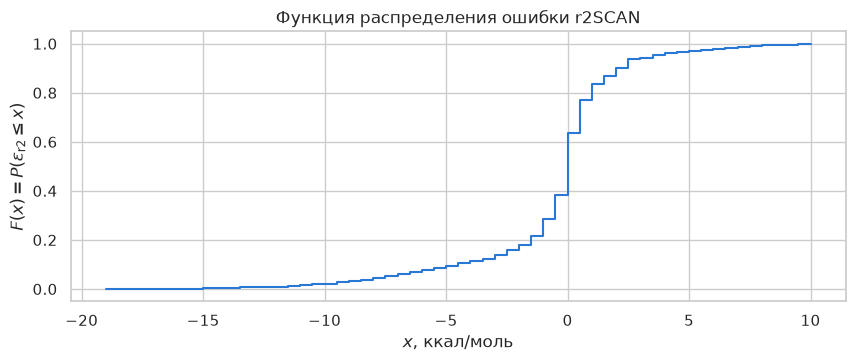

In [42]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(tab.index, tab.F, where="post", color=COL["r2SCAN"])
ax.set_xlabel(r"$x$, ккал/моль"); ax.set_ylabel(r"$F(x)=P(\varepsilon_\mathrm{r2}\leq x)$")
ax.set_title("Функция распределения ошибки r2SCAN")
plt.show()

#### Матожидание, дисперсия, медиана, мода
$$\mathbb E X=\sum_i x_i p_i,\qquad \mathbb D X=\sum_i (x_i-\mathbb E X)^2p_i,\qquad \operatorname{Mo}=\arg\max_i p_i,$$
медиана — значение, где $F(x)$ впервые достигает 0.5.

In [43]:
E = (tab.index * tab.p_i).sum()
D = ((tab.index - E) ** 2 * tab.p_i).sum()
Med = tab.index[tab.F >= 0.5][0]
Mo = tab.p_i.idxmax()
pd.DataFrame({"по таблице p_i (округлённые)": [E, D, np.sqrt(D), Med, Mo],
              "pandas (исходные данные)": [x.mean(), x.var(ddof=0), x.std(ddof=0), x.median(), np.nan]},
             index=["матожидание", "дисперсия", "станд. откл.", "медиана", "мода"]).round(3)

,по таблице p_i (округлённые),pandas (исходные данные)
матожидание,-0.526,-0.529
дисперсия,10.440,10.478
станд. откл.,3.231,3.237
медиана,0.000,0.010
мода,0.000,NaN


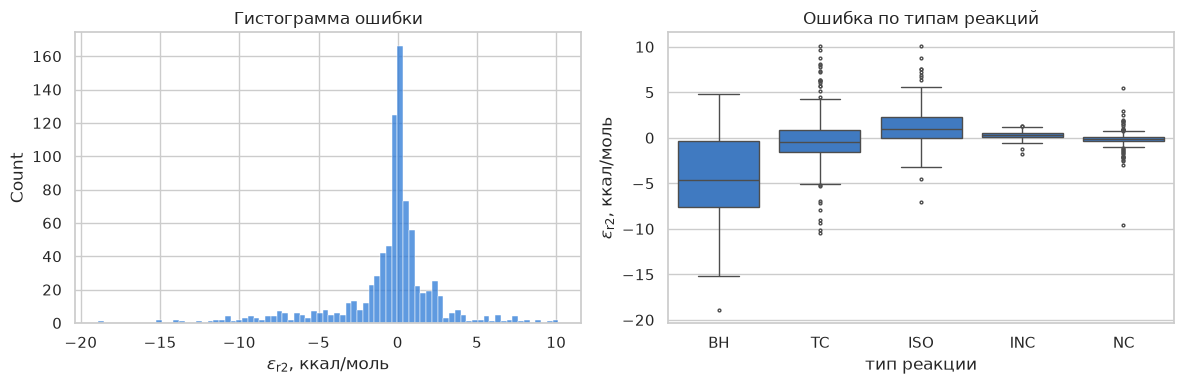

,count,mean,median,std
type,,,,
BH,140,-4.57,-4.67,4.52
TC,203,-0.15,-0.48,3.25
ISO,162,1.22,0.92,2.28
INC,152,0.32,0.27,0.42
NC,204,-0.16,-0.10,1.09


In [44]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x, bins=80, ax=ax[0], color=COL["r2SCAN"])
ax[0].set_xlabel(r"$\varepsilon_\mathrm{r2}$, ккал/моль"); ax[0].set_title("Гистограмма ошибки")
sns.boxplot(data=df, x="type", y="e_r2", order=TYPES, ax=ax[1], color=COL["r2SCAN"], fliersize=2)
ax[1].set_ylabel(r"$\varepsilon_\mathrm{r2}$, ккал/моль"); ax[1].set_xlabel("тип реакции"); ax[1].set_title("Ошибка по типам реакций")
plt.tight_layout(); plt.show()
df.groupby("type").e_r2.agg(["count", "mean", "median", "std"]).loc[TYPES].round(2)

Что видно: распределение имеет явную острою вершину, с длинным левым хвостом. Хвост дают барьеры реакций (на самом деле мы бы сказади что это из-за архитектуры завязаной только на констрейнах + нормах не связанных с такими крупными молекулами) (BH): r2SCAN систематически занижает барьеры примерно на 4.6 ккал/моль. У разных типов реакций масштаб ошибок отличается в 10 раз, поэтому данные стоит нормализовать(ну и потому что так сказано в задании ;) ).

Нормализация
1. Стандартизация $u=\dfrac{\varepsilon-\bar\varepsilon}{s}$: среднее 0, дисперсия 1. Если бы ошибка была нормальной, $u$ имела бы стандартное нормальное распределение $N(0,1)$, и вероятности можно было бы брать из одной таблицы.
2. Нормировка на погрешность эталона $z=\varepsilon/s_\mathrm{ref}$: ошибка в единицах «точности эталона». Так ошибка 0.3 ккал/моль на слабых взаимодействиях становится сравнимой с ошибкой 3 ккал/моль на барьерах.

          u_r2     z_r2
count  861.000  861.000
mean     0.000   -0.080
std      1.000    4.367
min     -5.669  -40.174
25%     -0.129   -1.772
50%      0.166    0.017
75%      0.364    2.206
max      3.292   25.217


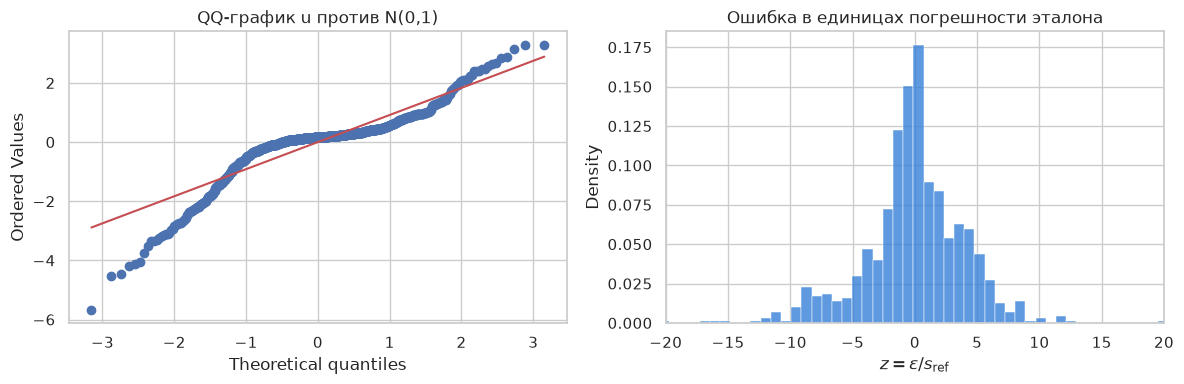

In [45]:
df["u_r2"] = (df.e_r2 - df.e_r2.mean()) / df.e_r2.std()
df["z_r2"] = df.e_r2 / df.s_ref
print(df[["u_r2", "z_r2"]].describe().round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
stats.probplot(df.u_r2, dist="norm", plot=ax[0])
ax[0].set_title("QQ-график u против N(0,1)")
sns.histplot(df.z_r2, bins=80, stat="density", ax=ax[1], color=COL["r2SCAN"])
ax[1].set_xlim(-20, 20); ax[1].set_xlabel(r"$z=\varepsilon/s_\mathrm{ref}$"); ax[1].set_title("Ошибка в единицах погрешности эталона")
plt.tight_layout(); plt.show()

На QQ-графике ( называется Quantile-Quantile plot магическая штука чем дальше от прямой(красной у нас посторена по 25 и 75 процентилю) тем больше отличие от нормального распределения каждая точка ставиться при опр. процентиле по Y наши данные по X данные теоретические) точки уходят от прямой на краях: хвосты у ошибки тяжелее нормальных, и стандартизация не делает её нормальной.

 Подбор распределения для $z$
Сравним нормальное распределение и распределение Лапласа (критерий Колмогорова–Смирнова(статичтический тест для проверки насколько рапределение подходит под наши данные (честно сильно с устройством тестов не разбирались но там смотриться максимальное расхождение и p-value говорит о том с каким шансом можно получить такое расхождение случайно)), параметры оценены по тем же данным, поэтому p-value немного завышен).

нормальное:  mu = -0.08, sigma = 4.36,  KS p = 1e-08
Лаплас:      mu = 0.02, b = 2.97,      KS p = 0.44


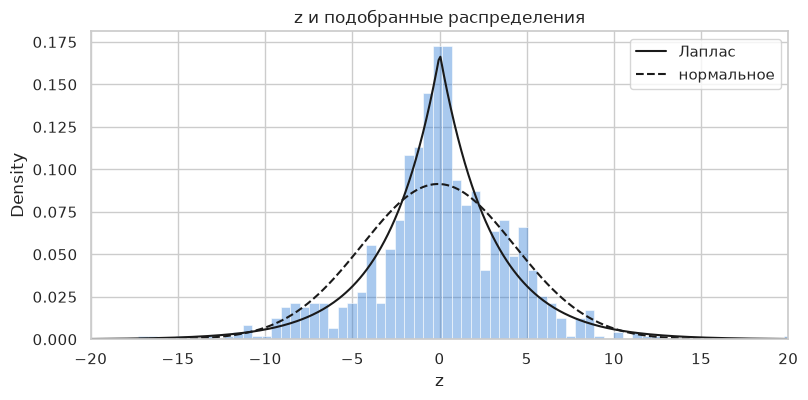

In [46]:
z = df.z_r2
mu_n, sd_n = stats.norm.fit(z)
mu_l, b_l = stats.laplace.fit(z)
print(f"нормальное:  mu = {mu_n:.2f}, sigma = {sd_n:.2f},  KS p = {stats.kstest(z, stats.norm.cdf, args=(mu_n, sd_n)).pvalue:.2g}")
print(f"Лаплас:      mu = {mu_l:.2f}, b = {b_l:.2f},      KS p = {stats.kstest(z, stats.laplace.cdf, args=(mu_l, b_l)).pvalue:.2g}")

grid = np.linspace(-20, 20, 400)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(z, bins=120, stat="density", ax=ax, color=COL["r2SCAN"], alpha=0.4)
ax.plot(grid, stats.laplace.pdf(grid, mu_l, b_l), "k-", label="Лаплас")
ax.plot(grid, stats.norm.pdf(grid, mu_n, sd_n), "k--", label="нормальное")
ax.set_xlim(-20, 20); ax.set_xlabel("z"); ax.legend(); ax.set_title("z и подобранные распределения")
plt.show()

 Распределение Лапласа
$$f(x)=\frac{1}{2b}e^{-|x-\mu|/b},\qquad
F(x)=\begin{cases}\frac12e^{(x-\mu)/b},&x<\mu\\[2pt]1-\frac12e^{-(x-\mu)/b},&x\ge\mu\end{cases}$$
* $\mathbb EX=\operatorname{Med}X=\operatorname{Mo}X=\mu$, $\ \mathbb DX=2b^2$;
* эксцесс равен 3 (у нормального 0): пик острее, хвосты тяжелее, как в наших данных;
* оценки по данным: $\hat\mu$ = медиана, $\hat b=\frac1n\sum|x_i-\hat\mu|$. При $\mu\approx0$ это просто средняя абсолютная ошибка (MAE), главная метрика в DFT-бенчмарках. MAE оказывается «родной» мерой разброса именно для лапласовских ошибок.

Тяжёлые хвосты понятны: реакции разных наборов имеют разный масштаб ошибок, и общее распределение — смесь узких и широких «колоколов».

Нормализация 3 — стандартизация внутри набора

Обе нормализации выше «глобальные»: у $u$ одно среднее и одно $s$ на все 861 реакцию, у $z$ мы делим на погрешность эталона, но систематический сдвиг набора не убираем. А из EDA видно, что тяжёлые хвосты получаются из смеси наборов с разным масштабом ошибок **и** разным смещением (барьеры в среднем −4.6 ккал/моль). Попробуем убрать оба эффекта сразу — стандартизуем ошибку внутри каждого набора:
$$w=\frac{\varepsilon-\bar\varepsilon_\text{набора}}{s_\text{набора}}.$$
Смысл $w$: насколько реакция необычна *для своего набора*, а не насколько велика ошибка вообще. Если хвосты действительно появляются из-за смешивания наборов, после такой нормализации распределение должно стать близким к нормальному.

,асимметрия,эксцесс,Шапиро p,KS p (нормальное)
u: глобальная стандартизация,-1.31,4.78,8e-29,1e-30
z: на погрешность эталона,-1.01,10.5,2e-21,1e-08
w: внутри набора,-0.28,1.56,1e-08,0.02


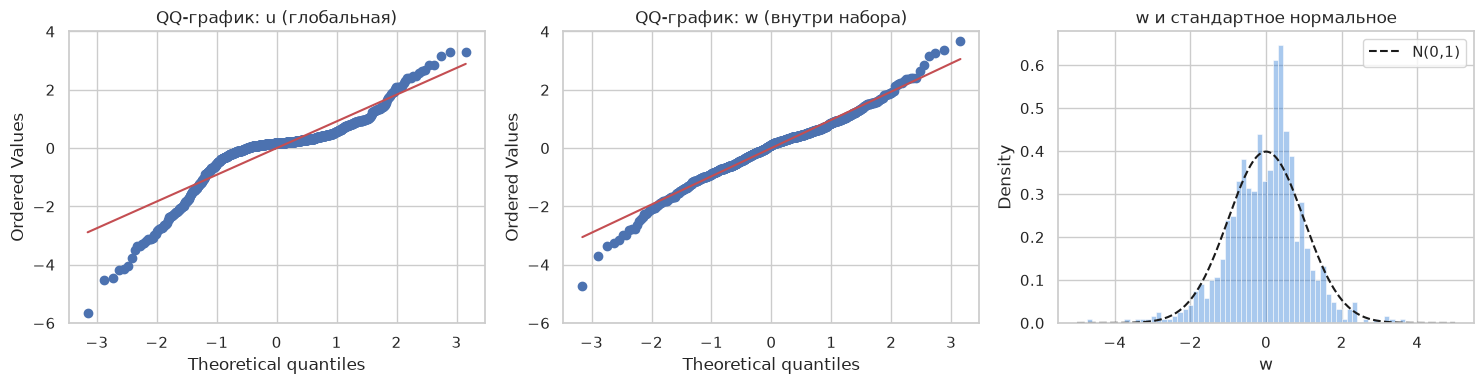

In [10]:
g_ds = df.groupby("dataset").e_r2
df["w_r2"] = (df.e_r2 - g_ds.transform("mean")) / g_ds.transform("std")

# сравним три нормализации: насколько каждая похожа на нормальное распределение
norm_cmp = {}
for col, name in [("u_r2", "u: глобальная стандартизация"), ("z_r2", "z: на погрешность эталона"), ("w_r2", "w: внутри набора")]:
    v = df[col]
    norm_cmp[name] = {"асимметрия": round(stats.skew(v), 2), "эксцесс": round(stats.kurtosis(v), 2),
                      "Шапиро p": f"{stats.shapiro(v).pvalue:.1g}",
                      "KS p (нормальное)": f"{stats.kstest((v - v.mean()) / v.std(), 'norm').pvalue:.1g}"}
display(pd.DataFrame(norm_cmp).T)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
stats.probplot(df.u_r2, dist="norm", plot=ax[0]); ax[0].set_title("QQ-график: u (глобальная)")
stats.probplot(df.w_r2, dist="norm", plot=ax[1]); ax[1].set_title("QQ-график: w (внутри набора)")
for a in ax[:2]:
    a.set_ylim(-6, 4)
grid_w = np.linspace(-5, 5, 400)
sns.histplot(df.w_r2, bins=60, stat="density", ax=ax[2], color=COL["r2SCAN"], alpha=0.4)
ax[2].plot(grid_w, stats.norm.pdf(grid_w), "k--", label="N(0,1)")
ax[2].set_xlabel("w"); ax[2].legend(); ax[2].set_title("w и стандартное нормальное")
plt.tight_layout(); plt.show()

Что получилось:
* эксцесс упал с 4.8 (у $u$) до 1.6, асимметрия — с −1.3 до −0.3. QQ-график $w$ почти прямой, отклонения остались только на самых краях.
* У $z$ эксцесс даже больше, чем у $u$ (10.5): деление на погрешность эталона хорошо ложится на Лапласа, но от нормального распределения уводит ещё дальше. $w$ — единственная из трёх нормализаций, после которой распределение близко к нормальному.
* Строго нормальным $w$ всё равно не стало (Шапиро и KS отвергают на уровне 0.05; при $n=861$ тесты замечают даже небольшие отличия, а KS ещё и с параметрами, оценёнными по тем же данным).
* Главный вывод: тяжёлые хвосты $\varepsilon_\mathrm{r2}$ в основном объясняются тем, что мы смешали наборы с разным масштабом и сдвигом. Внутри одного набора ошибки ведут себя почти «нормально».

Минусы этой нормализации:
* $w$ убирает систематическую ошибку набора — а это как раз главная информация о функционале (занижение барьеров у $w$ пропадает). Поэтому для сравнения функционалов $w$ не годится; она полезна, чтобы искать реакции, «странные» для своего набора.
* В маленьких наборах $s_\text{набора}$ оценивается грубо. Например, при выборочной стандартизации $|w|\le (n-1)/\sqrt n$, т.е. в ADIM6 ($n=4$) $|w|$ не может быть больше 1.5, как бы реакция ни выделялась.


 Генеральная и выборочная совокупности

Генеральная совокупность — все $N=861$ реакция. Возьмём выборку $n=100$ двумя способами: с возвращением (реакция может попасть дважды) и без возвращения, и сравним статистики с генеральной.(к сожалению интересных выборок не нашли ;()

In [47]:
rng = np.random.default_rng(1)
n = 100
s_with = rng.choice(x.values, n, replace=True)
s_without = rng.choice(x.values, n, replace=False)
cmp = pd.DataFrame({name: [len(v), v.mean(), np.median(v), v.std(ddof=1), np.abs(v).mean()]
                    for name, v in [("генеральная", x.values), ("с возвращением", s_with), ("без возвращения", s_without)]},
                   index=["объём", "среднее", "медиана", "станд. откл.", "MAE"]).T
cmp["KS p (с генеральной)"] = [np.nan, stats.ks_2samp(s_with, x).pvalue, stats.ks_2samp(s_without, x).pvalue]
cmp.round(3)

,объём,среднее,медиана,станд. откл.,MAE,KS p (с генеральной)
генеральная,861.0,-0.529,0.010,3.239,1.893,NaN
с возвращением,100.0,-0.238,-0.156,2.896,1.756,0.115
без возвращения,100.0,-0.165,-0.028,2.509,1.445,0.542


Одна выборка может случайно оказаться удачной или неудачной. Поэтому повторим выборку 2000 раз и сравним разброс выборочного среднего с теорией:
$$\text{с возвращением: }\ \sigma_{\bar x}=\frac{\sigma}{\sqrt n},\qquad \text{без возвращения: }\ \sigma_{\bar x}=\frac{\sigma}{\sqrt n}\sqrt{\frac{N-n}{N-1}}.$$
Без возвращения разброс меньше: каждая реакция даёт новую информацию, а совокупность конечна.

In [48]:
N, sigma = len(x), x.std(ddof=0)
m_with = [rng.choice(x.values, n, replace=True).mean() for _ in range(2000)]
m_without = [rng.choice(x.values, n, replace=False).mean() for _ in range(2000)]
pd.DataFrame({"эксперимент": [np.std(m_with), np.std(m_without)],
              "теория": [sigma / np.sqrt(n), sigma / np.sqrt(n) * np.sqrt((N - n) / (N - 1))]},
             index=["с возвращением", "без возвращения"]).round(4)

,эксперимент,теория
с возвращением,0.3316,0.3237
без возвращения,0.3090,0.3045


Проверка гипотез

* Г1: $\varepsilon_\mathrm{r2}$ распределена нормально (критерий Шапиро–Уилка (статистический тест для проверки гипотезы: "Данные происходят из нормального распределения")).
* Г2: r2SCAN не ошибается систематически на барьерах, т.е. медиана ошибки на BH равна 0 (одновыборочный критерий Уилкоксона).

In [49]:
p1 = stats.shapiro(x).pvalue
bh = df.loc[df.type == "BH", "e_r2"]
p2 = stats.wilcoxon(bh).pvalue
print(f"Г1 (нормальность):        p = {p1:.2g}  ->", "отвергаем" if p1 < 0.05 else "не отвергаем")
print(f"Г2 (нет смещения на BH):  p = {p2:.2g}  ->", "отвергаем" if p2 < 0.05 else "не отвергаем", f"(медиана ошибки на BH = {bh.median():.2f})")

Г1 (нормальность):        p = 8.5e-29  -> отвергаем
Г2 (нет смещения на BH):  p = 8.5e-18  -> отвергаем (медиана ошибки на BH = -4.67)


Выводы по первой случайной велечине

* Ошибка r2SCAN — случайная величина: внутри одного набора реакций она меняется, формулы для неё нет.
* Распределение не нормальное (Шапиро $p\ll0.05$): острый пик около нуля и длинный левый хвост. Хвост дают барьеры, которые r2SCAN систематически занижает (H2 отвергнута, медиана −4.7 ккал/моль).
* После нормировки на погрешность эталона ошибка хорошо описывается распределением Лапласа ($b\approx3$: r2SCAN ошибается в среднем на три погрешности эталона).
* Оценки среднего и медианы состоятельны. Выборка из 100 реакций хорошо передаёт свойства генеральной совокупности. Выборка без возвращения точнее, что совпадает с формулой с поправкой $\sqrt{(N-n)/(N-1)}$.

Случайнаня величина 2 — ошибка NN-r2SCAN $\varepsilon_\mathrm{NN}$ <a id="rv2"></a>
То же событие $\omega$ (реакция) и та же природа величины, но другой функционал:
$$\varepsilon_\mathrm{NN}(\omega)=E_\mathrm{NN}(\omega)-E_\mathrm{ref}(\omega).$$
NN-r2SCAN — это r2SCAN плюс небольшая нейросетевая поправка, поэтому ожидается, что $\varepsilon_\mathrm{NN}$ сильно зависит от $\varepsilon_\mathrm{r2}$. Это нужно проверить: от ответа зависит, какими методами можно сравнивать функционалы.

EDA 

,r2SCAN,NN-r2SCAN
count,861.000,861.000
mean,-0.529,-0.658
std,3.239,3.335
min,-18.891,-19.029
25%,-0.948,-0.775
50%,0.010,0.036
75%,0.649,0.569
max,10.132,9.571
MAE,1.893,1.870
эксцесс,4.776,5.585


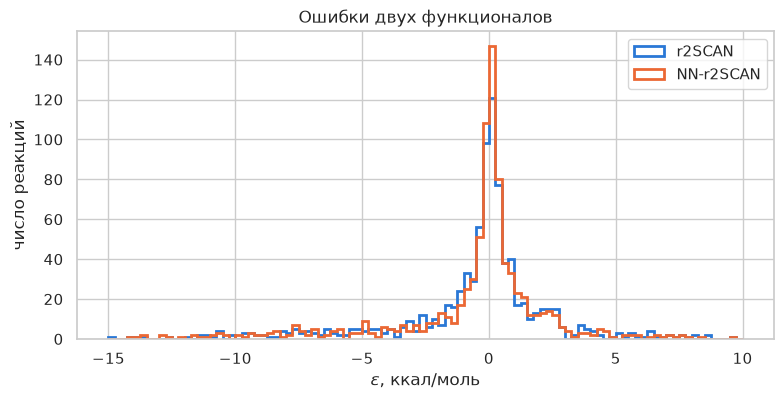

z_NN ~ Лаплас: mu = 0.11, b = 2.86, KS p = 0.081


In [50]:
df["z_nn"] = df.e_nn / df.s_ref
both = pd.DataFrame({"r2SCAN": df.e_r2.describe(), "NN-r2SCAN": df.e_nn.describe()})
both.loc["MAE"] = [df.e_r2.abs().mean(), df.e_nn.abs().mean()]
both.loc["эксцесс"] = [stats.kurtosis(df.e_r2), stats.kurtosis(df.e_nn)]
display(both.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(-15, 10, 101)
for m, col in [("r2SCAN", "e_r2"), ("NN-r2SCAN", "e_nn")]:
    ax.hist(df[col], bins=bins, histtype="step", lw=2, color=COL[m], label=m)
ax.set_xlabel(r"$\varepsilon$, ккал/моль"); ax.set_ylabel("число реакций"); ax.legend(); ax.set_title("Ошибки двух функционалов")
plt.show()

mu_l2, b_l2 = stats.laplace.fit(df.z_nn)
print(f"z_NN ~ Лаплас: mu = {mu_l2:.2f}, b = {b_l2:.2f}, KS p = {stats.kstest(df.z_nn, stats.laplace.cdf, args=(mu_l2, b_l2)).pvalue:.2g}")

Распределения почти совпадают. У NN чуть меньше MAE и чуть уже центральная часть; $z_\mathrm{NN}$ так же описывается распределением Лапласа.

Независимость

Г3: $\varepsilon_\mathrm{r2}$ и $\varepsilon_\mathrm{NN}$ независимы. 

Проверяем корреляцией Пирсона и Спирмена и критерием $\chi^2$ по таблице сопряжённости. Для таблицы каждую ошибку делим на 4 группы по квартилям. Если величины независимы, реакция из первой четверти по r2SCAN может с равной вероятностью попасть в любую четверть по NN.

Пирсон
$r = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}
         {\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2 \cdot \sum_{i=1}^{n}(y_i - \bar{y})^2}}$

Спирмен (упрощённый)
$\rho = 1 - \frac{6\sum_{i=1}^{n} d_i^2}{n(n^2 - 1)}$

Хи-квадрат
$\chi^2 = \sum_{i=1}^{r}\sum_{j=1}^{c} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, 
\quad E_{ij} = \frac{R_i \cdot C_j}{N}$
\begin{aligned}
    &\text{где:} \\
    &\quad O_{ij} \text{ --- наблюдаемая частота в ячейке } (i,j) \text{ таблицы сопряжённости,} \\
    &\quad E_{ij} \text{ --- ожидаемая частота при гипотезе независимости,} \\
    &\quad r \text{ --- число строк, } c \text{ --- число столбцов.} \\[1em]
    &\text{Ожидаемая частота:} \quad E_{ij} = \frac{R_i \cdot C_j}{N}, \\
    &\text{где } R_i = \sum_{j=1}^{c} O_{ij}, \quad 
      C_j = \sum_{i=1}^{r} O_{ij}, \quad 
      N = \sum_{i=1}^{r}\sum_{j=1}^{c} O_{ij}. \\[1em]
    &\text{Число степеней свободы:} \quad \nu = (r-1)(c-1).
\end{aligned}

Это метрики показывающие корреляцию между двумя переменными +1 - идеальная связь (чем больше X, тем больше Y) 0 - связи нет -1 - связь обратная (чем больше X, тем больше Y)


Пирсон r = 0.908 (p = 0);  Спирмен rho = 0.891;  chi2 = 1644, p = 0


ε_NN,Q1,Q2,Q3,Q4
ε_r2,,,,
Q1,185,20,7,4
Q2,17,171,26,1
Q3,4,22,175,14
Q4,10,2,7,196


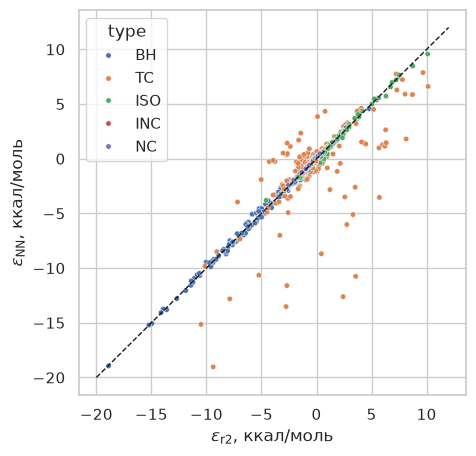

In [51]:
pear = stats.pearsonr(df.e_r2, df.e_nn)
spear = stats.spearmanr(df.e_r2, df.e_nn)
table = pd.crosstab(pd.qcut(df.e_r2, 4, labels=["Q1", "Q2", "Q3", "Q4"]),
                    pd.qcut(df.e_nn, 4, labels=["Q1", "Q2", "Q3", "Q4"]))
chi = stats.chi2_contingency(table)
print(f"Пирсон r = {pear.statistic:.3f} (p = {pear.pvalue:.1g});  Спирмен rho = {spear.statistic:.3f};  chi2 = {chi.statistic:.0f}, p = {chi.pvalue:.1g}")
display(table.rename_axis(index="ε_r2", columns="ε_NN"))

fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(data=df, x="e_r2", y="e_nn", hue="type", hue_order=TYPES, s=15, ax=ax)
ax.plot([-20, 12], [-20, 12], "k--", lw=1)
ax.set_xlabel(r"$\varepsilon_\mathrm{r2}$, ккал/моль"); ax.set_ylabel(r"$\varepsilon_\mathrm{NN}$, ккал/моль")
plt.show()

Выводы по Случайной величине 2
* Распределение $\varepsilon_\mathrm{NN}$ почти такое же, как у $\varepsilon_\mathrm{r2}$: в единицах погрешности эталона это тоже распределение Лапласа.
* Гипотеза о независимости (Г3) отвергается: $r\approx0.91$, почти все реакции остаются в «своей» четверти. Это ожидаемо, ведь NN — малая поправка к r2SCAN.
* Следствие: сравнивать функционалы как две независимые выборки нельзя. Нужно смотреть на разность на каждой реакции, то есть на парные методы. Поэтому третья величина — $\Delta$.

Случайная велечина 3 — выигрыш NN на реакции $\Delta$ <a id="rv3"></a>

$$\Delta(\omega)=|\varepsilon_\mathrm{NN}(\omega)|-|\varepsilon_\mathrm{r2}(\omega)|.$$
$\Delta<0$ — на этой реакции NN точнее, $\Delta>0$ — хуже. $\Delta$ — функция двух случайных величин, поэтому тоже случайная величина. Её среднее равно $\mathrm{MAE}_\mathrm{NN}-\mathrm{MAE}_\mathrm{r2}$, то есть основному показателю, по которому сравнивают функционалы.

EDA

count    861.000
mean      -0.022
std        1.097
min       -6.338
25%       -0.113
50%       -0.016
75%        0.062
max       10.754
Name: delta, dtype: float64
эксцесс: 41.5
доля реакций, где NN лучше (win rate): 0.599


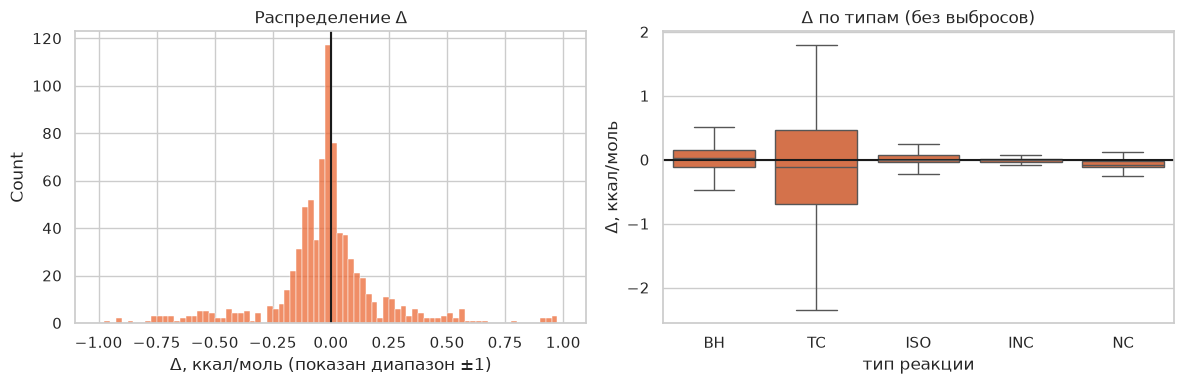

,count,mean,median,win rate
type,,,,
BH,140,-0.005,0.024,0.436
TC,203,-0.025,-0.118,0.606
ISO,162,-0.007,-0.002,0.512
INC,152,-0.006,-0.002,0.586
NC,204,-0.054,-0.079,0.784


In [52]:
df["delta"] = df.e_nn.abs() - df.e_r2.abs()
d = df.delta
print(d.describe().round(3))
print("эксцесс:", round(stats.kurtosis(d), 1))
print("доля реакций, где NN лучше (win rate):", round((d < 0).mean(), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(d, bins=np.linspace(-1, 1, 81), ax=ax[0], color=COL["NN-r2SCAN"])
ax[0].axvline(0, color="k"); ax[0].set_xlabel("Δ, ккал/моль (показан диапазон ±1)"); ax[0].set_title("Распределение Δ")
sns.boxplot(data=df, x="type", y="delta", order=TYPES, ax=ax[1], color=COL["NN-r2SCAN"], showfliers=False)
ax[1].axhline(0, color="k"); ax[1].set_ylabel("Δ, ккал/моль"); ax[1].set_xlabel("тип реакции"); ax[1].set_title("Δ по типам (без выбросов)")
plt.tight_layout(); plt.show()
df.groupby("type").delta.agg(["count", "mean", "median", lambda v: (v < 0).mean()]).loc[TYPES] \
  .rename(columns={"<lambda_0>": "win rate"}).round(3)

На большинстве реакций поправка меняет ошибку меньше чем на 0.1 ккал/моль, но есть редкие выбросы до ±10 ккал/моль (эксцесс > 40). Сравним три кандидата: нормальное, Лаплас и Коши.

,распределение,"параметры (loc, scale)",KS p
0,norm,"[-0.022, 1.097]",9.969452e-69
1,laplace,"[-0.016, 0.366]",8.457944e-24
2,cauchy,"[-0.019, 0.086]",1.050202e-01


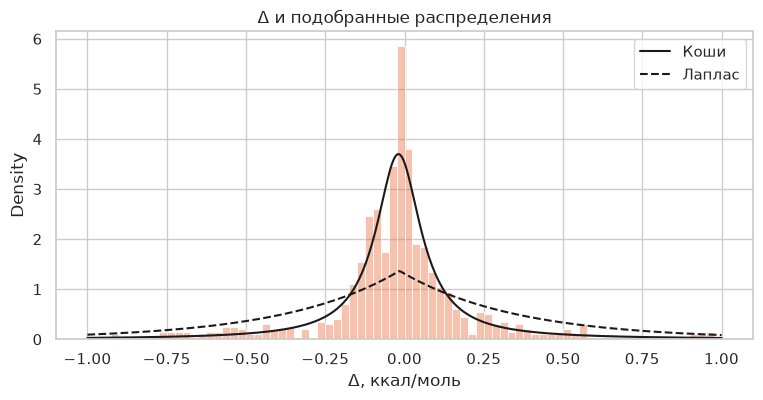

In [53]:
res = []
for name in ["norm", "laplace", "cauchy"]:
    params = getattr(stats, name).fit(d)
    res.append([name, np.round(params, 3), stats.kstest(d, getattr(stats, name).cdf, args=params).pvalue])
display(pd.DataFrame(res, columns=["распределение", "параметры (loc, scale)", "KS p"]))

loc_c, sc_c = stats.cauchy.fit(d)
grid = np.linspace(-1, 1, 400)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(d, bins=np.linspace(-1, 1, 81), stat="density", ax=ax, color=COL["NN-r2SCAN"], alpha=0.4)
ax.plot(grid, stats.cauchy.pdf(grid, loc_c, sc_c), "k-", label="Коши")
ax.plot(grid, stats.laplace.pdf(grid, *stats.laplace.fit(d)), "k--", label="Лаплас")
ax.set_xlabel("Δ, ккал/моль"); ax.legend(); ax.set_title("Δ и подобранные распределения")
plt.show()

#### Распределение Коши
$$f(x)=\frac{1}{\pi\gamma\left[1+\left(\frac{x-x_0}{\gamma}\right)^2\right]},\qquad F(x)=\frac12+\frac1\pi\arctan\frac{x-x_0}{\gamma}.$$
* Медиана и мода равны $x_0$, а матожидания и дисперсии не существует: интеграл $\int|x|f(x)\,dx$ расходится из-за очень тяжёлых хвостов.
* Поэтому выборочное среднее распределения Коши не сходится к одному числу при росте выборки (закон больших чисел не работает), а выборочная медиана сходится.
* Для нас это значит, что «средний выигрыш» $\bar\Delta$ (разность MAE) — ненадёжная характеристика: несколько реакций с большим $|\Delta|$ могут перевернуть вывод. Типичный эффект лучше описывает медиана.



Проверка гипотез — главный вопрос: лучше ли NN?
* Г4 (знаковый критерий): NN выигрывает и проигрывает одинаково часто, $P(\Delta<0)=0.5$.
* Г5 (Уилкоксон): медиана $\Delta$ равна 0.
* Г6 (парный t-тест): среднее $\Delta$ равно 0, т.е. $\mathrm{MAE}_\mathrm{NN}=\mathrm{MAE}_\mathrm{r2}$.

In [54]:
wins, n_nz = int((d < 0).sum()), int((d != 0).sum())
p4 = stats.binomtest(wins, n_nz, 0.5).pvalue
p5 = stats.wilcoxon(d).pvalue
p6 = stats.ttest_rel(df.e_nn.abs(), df.e_r2.abs()).pvalue
for h, txt, p in [("H4", f"P(Δ<0) = 0.5   (win rate = {wins / n_nz:.3f})", p4),
                  ("H5", f"медиана Δ = 0  (медиана = {d.median():+.3f})", p5),
                  ("H6", f"среднее Δ = 0  (ΔMAE = {d.mean():+.3f})", p6)]:
    print(f"{h}: {txt:40s} p = {p:.2g} ->", "отвергаем" if p < 0.05 else "не отвергаем")

H4: P(Δ<0) = 0.5   (win rate = 0.599)        p = 6.2e-09 -> отвергаем
H5: медиана Δ = 0  (медиана = -0.016)        p = 4.2e-06 -> отвергаем
H6: среднее Δ = 0  (ΔMAE = -0.022)           p = 0.55 -> не отвергаем


In [58]:
# то же по типам реакций (критерий Уилкоксона; 5 проверок, поэтому порог 0.05/5 = 0.01, поправка Бонферрони)
by_type = pd.DataFrame({t: {"медиана Δ": df.delta[df.type == t].median(),
                            "p": stats.wilcoxon(df.delta[df.type == t]).pvalue} for t in TYPES}).T
by_type["вывод (p < 0.01)"] = np.where(by_type.p < 0.01, np.where(by_type["медиана Δ"] < 0, "NN лучше", "NN хуже"), "нет разницы")
by_type

,медиана Δ,p,вывод (p < 0.01)
BH,0.024222,2.702707e-01,нет разницы
TC,-0.118431,3.087669e-02,нет разницы
ISO,-0.001926,4.304121e-01,нет разницы
INC,-0.002070,4.080856e-02,нет разницы
NC,-0.079493,4.940873e-13,NN лучше


Выводы по случайной величине 3
* $\Delta$ — величина с очень острым пиком около нуля и редкими большими выбросами. Из трёх кандидатов лучше всего подходит распределение Коши, у которого нет матожидания. Поэтому для сравнения функционалов надёжнее медиана и доля побед, чем разность MAE.
* Знаковый критерий и Уилкоксон (H4, H5) отвергаются: на типичной реакции NN-r2SCAN точнее r2SCAN (выигрывает на ~60 % реакций).
* Парный t-тест (H6) не отвергается ($p\approx0.55$): средняя ошибка (MAE) значимо не изменилась. NN часто выигрывает понемногу, но изредка проигрывает помногу .
* По типам значимое улучшение есть только для нековалентных взаимодействий (NC). На барьерах и изомеризации поправка ничего не меняет.

Дополнительно: хвосты как отдельная выборка <a id="tails"></a>

Пока разбирали все три величины, постоянно упирались в хвосты: у ошибки r2SCAN длинный левый хвост, у $\Delta$ редкие, но огромные выбросы, из-за которых t‑тест вообще ничего не видит. Поэтому решили посмотреть на хвосты отдельно, как на самостоятельную выборку, и понять:
1. кто туда попадает — случайные реакции или какая-то конкретная химия;
2. насколько хвост тяжёлый — как у Лапласа (экспонента) или как у Коши (степень);
3. помогает ли нейросеть там, где r2SCAN ошибается сильнее всего (для разработчика метода это самый интересный вопрос);
4. правда ли, что именно хвосты $\Delta$ «съедают» выигрыш NN по MAE.

**1. Кто сидит в хвостах**

Хвостом считаем 5 % самых маленьких и 5 % самых больших ошибок $\varepsilon_\mathrm{r2}$, это по 44 реакции с каждой стороны. Дальше просто считаем, сколько реакций каждого типа попало в хвосты, а сколько в центр.

Г7: в хвостах типы реакций встречаются так же часто, как в центре (проверяем тем же $\chi^2$, что и в Г3, только таблица теперь «часть распределения × тип реакции»).

In [20]:
q_lo, q_hi = df.e_r2.quantile([0.05, 0.95])
df["tail_r2"] = np.select([df.e_r2 <= q_lo, df.e_r2 >= q_hi], ["левый хвост", "правый хвост"], "центр")
print(f"границы хвостов: ε ≤ {q_lo:.2f} и ε ≥ {q_hi:.2f} ккал/моль")

tail_tab = pd.crosstab(df.tail_r2, df.type)[TYPES]
display(tail_tab)
chi_t = stats.chi2_contingency(tail_tab)
print(f"Г7: chi2 = {chi_t.statistic:.0f}, p = {chi_t.pvalue:.1g} ->", "отвергаем" if chi_t.pvalue < 0.05 else "не отвергаем")
for part in ["левый хвост", "правый хвост"]:
    print(f"{part}, главные наборы:", df[df.tail_r2 == part].dataset.value_counts().head(4).to_dict())

границы хвостов: ε ≤ -7.39 и ε ≥ 3.59 ккал/моль


type,BH,TC,ISO,INC,NC
tail_r2,,,,,
левый хвост,38,5,0,0,1
правый хвост,1,25,17,0,1
центр,101,173,145,152,202


Г7: chi2 = 221, p = 3e-43 -> отвергаем
левый хвост, главные наборы: {'WCPT26': 16, 'PX9': 8, 'BH28': 7, 'BHDIV7': 4}
правый хвост, главные наборы: {'RC21': 14, 'Styrene42': 9, 'BDE99nonMR': 4, 'DARC': 4}


Тут всё очень наглядно: хвосты совсем не случайные (Г7 отвергается, $p\sim10^{-43}$).
* В левом хвосте (r2SCAN сильно занижает) почти одни барьеры — 38 из 44. Больше всего WCPT26 (перенос протона в кластерах воды), PX9 и BH28. Для химика это не сюрприз: r2SCAN, как и большинство функционалов такого типа, занижает барьеры из-за ошибки делокализации, а на переносе протона особенно сильно.
* В правом хвосте (r2SCAN сильно завышает) — термохимия и изомеризация, в первую очередь RC21 и Styrene42.
* Нековалентных взаимодействий (INC, NC) в хвостах почти нет, хотя это треть всех реакций: на них r2SCAN ошибается по мелочи.

То есть «длинный хвост» — это не какая-то загадочная особенность распределения, а просто другая группа реакций со своим смещением. С нормализацией 3 это сходится: убрали сдвиг и масштаб набора — и хвосты почти пропали.

**2. Насколько хвост тяжёлый**

Раньше мы подбирали распределение по всей выборке сразу, а там острый пик в центре весит гораздо больше, чем хвосты. Хотелось проверить отдельно именно хвост. Оказалось, что для этого есть целая теория — теория экстремальных значений. Главная идея (теорема Пикандса–Балкемы–де Хаана): если взять достаточно высокий порог $t$ и смотреть только на то, насколько значения его превышают, $Y=X-t$, то почти для любого распределения эти превышения описываются одним семейством — обобщённым распределением Парето (GPD):
$$F(y)=1-\left(1+\xi\frac{y}{\sigma}\right)^{-1/\xi},\qquad y\ge0 .$$
Нас интересует в основном параметр $\xi$, он и говорит, какой хвост:
* $\xi=0$ — хвост экспоненциальный, $F(y)=1-e^{-y/\sigma}$. Так у нормального и у Лапласа (у Лапласа превышения вообще ровно экспоненциальные: у экспоненты нет «памяти»);
* $\xi>0$ — хвост степенной, тяжёлый: $P(X>x)\sim x^{-1/\xi}$. Чем больше $\xi$, тем меньше моментов существует; у Коши $\xi=1$, поэтому нет даже матожидания;
* $\xi<0$ — у хвоста есть «потолок», дальше которого значения не уходят.

Получается независимая проверка того, что мы делали раньше: для ошибки ждём $\xi\approx0$ (Лаплас), для $\Delta$ — явно больше нуля (Коши). Берём модули величин, порог — 90 % квантиль (86 превышений), а доверительный интервал для $\xi$ получаем бутстрепом: 300 раз пересобираем превышения с возвращением (как в разделе про выборки) и смотрим, как гуляет $\xi$.

,порог,превышений,ξ,σ,ξ: 95% ДИ,KS p (GPD),KS p (экспонента)
|ε_r2|,5.707,86,-0.169,3.428,"[-0.44, -0.05]",0.5289,0.2917
|z_r2|,6.913,86,0.252,2.179,"[-0.01, 0.45]",0.1613,0.0421
|Δ|,0.677,86,0.506,1.053,"[0.14, 0.84]",0.2408,0.0003


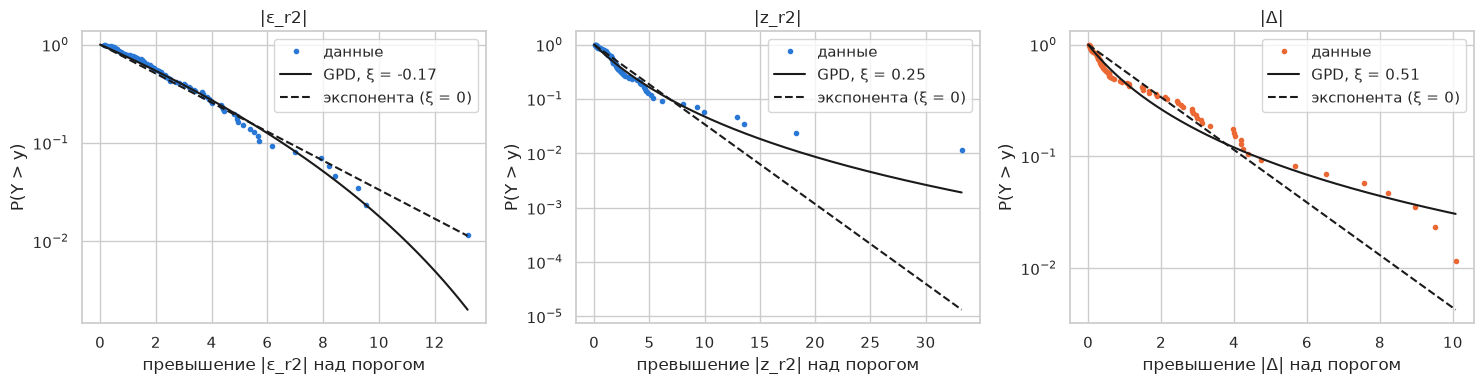

In [21]:
import warnings

def gpd_tail(v, q=0.9, n_boot=300, seed=0):
    # превышения |v| над порогом (квантиль q), подгонка GPD и бутстреп-интервал для ξ
    a = np.abs(np.asarray(v))
    t = np.quantile(a, q)
    y = a[a > t] - t
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        xi, _, sig = stats.genpareto.fit(y, floc=0)
        rng_b = np.random.default_rng(seed)
        boot = [stats.genpareto.fit(rng_b.choice(y, len(y)), floc=0)[0] for _ in range(n_boot)]
    lo, hi = np.quantile(boot, [0.025, 0.975])
    row = {"порог": round(t, 3), "превышений": len(y), "ξ": round(xi, 3), "σ": round(sig, 3),
           "ξ: 95% ДИ": f"[{lo:.2f}, {hi:.2f}]",
           "KS p (GPD)": round(stats.kstest(y, stats.genpareto.cdf, args=(xi, 0, sig)).pvalue, 4),
           "KS p (экспонента)": round(stats.kstest(y, stats.expon.cdf, args=(0, y.mean())).pvalue, 4)}
    return row, y

tails_shape, exc = {}, {}
for col, name in [("e_r2", "|ε_r2|"), ("z_r2", "|z_r2|"), ("delta", "|Δ|")]:
    tails_shape[name], exc[name] = gpd_tail(df[col])
display(pd.DataFrame(tails_shape).T)

# логарифмическая шкала по y: экспонента выглядит прямой, степенной хвост — выпуклой вверх кривой
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, y) in zip(ax, exc.items()):
    ys = np.sort(y)
    surv = 1 - np.arange(len(ys)) / len(ys)
    xi, sig = tails_shape[name]["ξ"], tails_shape[name]["σ"]
    gx = np.linspace(0, ys.max(), 200)
    a.semilogy(ys, surv, "o", ms=3, color=COL["NN-r2SCAN"] if name == "|Δ|" else COL["r2SCAN"], label="данные")
    a.semilogy(gx, stats.genpareto.sf(gx, xi, 0, sig), "k-", label=f"GPD, ξ = {xi:.2f}")
    a.semilogy(gx, stats.expon.sf(gx, 0, y.mean()), "k--", label="экспонента (ξ = 0)")
    a.set_xlabel(f"превышение {name} над порогом"); a.set_ylabel("P(Y > y)"); a.set_title(name); a.legend()
plt.tight_layout(); plt.show()

На графиках по оси y логарифм, поэтому экспонента выглядит прямой, а степенной хвост — кривой, которая загибается и уходит дальше вправо.
* $|\varepsilon_\mathrm{r2}|$: $\xi\approx-0.17$, экспоненту отвергнуть нельзя. Хвост лёгкий и даже немного обрезанный: самые большие ошибки r2SCAN упираются примерно в 19 ккал/моль. Значит, большой эксцесс (4.8) — это эффект смеси наборов, а не «настоящий» тяжёлый хвост. Приятно, что это совпало с выводом из пункта 1.
* $|z|$: $\xi\approx0.25$, но интервал задевает 0, и экспонента отвергается только на грани ($p\approx0.04$). Так что Лаплас для $z$ всё ещё нормальная модель, просто самые дальние точки у $z$ чуть тяжелее.
* $|\Delta|$: $\xi\approx0.5$, интервал $[0.14,\ 0.84]$ ноль не содержит, экспонента отвергается уверенно ($p\approx3\cdot10^{-4}$). Хвост у $\Delta$ правда степенной, примерно $P(|\Delta|>x)\sim x^{-2}$.

А тут мы немного поправили сами себя. В разделе про $\Delta$ мы сказали «Коши, матожидания нет». Но интервал для $\xi$ до 1 не доходит, то есть хвост у $\Delta$ тяжёлый, но легче, чем у Коши. Скорее всего, матожидание у $\Delta$ всё-таки есть, и разность MAE смысл имеет. Зато дисперсия на грани существования ($\xi\approx1/2$), поэтому среднее сходится очень медленно и его легко сдвигают несколько реакций. Коши хорошо описывает острый пик в центре, а хвост у неё тяжелее, чем у наших данных.

**3. Помогает ли NN там, где r2SCAN хуже всего**

Это вопрос уже скорее к разработчику метода: если нейросеть правда что-то исправляет, логично ждать, что сильнее всего она поможет там, где r2SCAN ошибается больше всего. Берём 10 % реакций с самой большой $|\varepsilon_\mathrm{r2}|$ (87 штук, дальше называем их «трудными») и сравниваем с остальными:
* смотрим, сколько трудных для r2SCAN реакций остаются среди 10 % худших и у NN. Если бы ошибки были независимы, было бы около 10 %;
* Г8: $\Delta$ на трудных и на остальных реакциях распределена одинаково (критерий Манна–Уитни — это как Уилкоксон, только для двух разных групп).

In [22]:
a_r2, a_nn = df.e_r2.abs(), df.e_nn.abs()
hard = a_r2 >= a_r2.quantile(0.9)          # 10 % худших реакций для r2SCAN
hard_nn = a_nn >= a_nn.quantile(0.9)       # 10 % худших реакций для NN
both_hard = (hard & hard_nn).sum()
print(f"трудных для r2SCAN: {hard.sum()}, из них трудных и для NN: {both_hard} "
      f"(доля {both_hard / hard.sum():.2f}, при независимости было бы ≈ 0.10)")
print("типы трудных реакций:", df[hard].type.value_counts().to_dict())

hard_cmp = pd.DataFrame({part: {"реакций": m.sum(), "win rate NN": (df.delta[m] < 0).mean(),
                                "медиана Δ": df.delta[m].median(),
                                "медиана Δ/|ε_r2| (отн. изменение)": (df.delta / a_r2)[m].median()}
                         for part, m in [("трудные (10 % худших)", hard), ("остальные", ~hard)]}).T
display(hard_cmp.round(3))

p8 = stats.mannwhitneyu(df.delta[hard], df.delta[~hard]).pvalue
print(f"Г8 (Δ на трудных и остальных распределена одинаково): p = {p8:.2g} ->", "отвергаем" if p8 < 0.05 else "не отвергаем")

трудных для r2SCAN: 87, из них трудных и для NN: 77 (доля 0.89, при независимости было бы ≈ 0.10)
типы трудных реакций: {'BH': 56, 'TC': 21, 'ISO': 9, 'NC': 1}


,реакций,win rate NN,медиана Δ,медиана Δ/|ε_r2| (отн. изменение)
трудные (10 % худших),87.0,0.540,-0.044,-0.004
остальные,774.0,0.606,-0.014,-0.031


Г8 (Δ на трудных и остальных распределена одинаково): p = 0.36 -> не отвергаем


Результат, честно говоря, немного грустный:
* 77 из 87 трудных реакций остаются трудными и для NN (89 % вместо 10 % при независимости). Это ещё раз подтверждает Г3: NN — это тот же r2SCAN с маленькой поправкой.
* Г8 не отвергается: на трудных реакциях NN выигрывает не чаще, а даже чуть реже (54 % против 61 %). Если смотреть в долях, на трудных реакциях поправка убирает примерно 0.4 % ошибки, на остальных — около 3 %.
* Что это значит для разработки: поправка слишком маленькая, чтобы вытащить систематические провалы r2SCAN (те же барьеры переноса протона). Если хочется улучшить именно хвост, таким реакциям надо давать отдельный вес в лоссе или делать поправку гибче — это сходится с идеями из итога спринта.

**4. Хвосты $\Delta$: кто на самом деле решает, у кого MAE меньше**

Теперь хвосты самой $\Delta$. Берём 5 % самых больших выигрышей NN ($\Delta\le q_{0.05}$) и 5 % самых больших проигрышей ($\Delta\ge q_{0.95}$) и смотрим, что это за реакции и сколько они вносят в сумму $\sum\Delta=n\cdot(\mathrm{MAE}_\mathrm{NN}-\mathrm{MAE}_\mathrm{r2})$.

In [23]:
d_lo, d_hi = df.delta.quantile([0.05, 0.95])
big_win, big_loss = df[df.delta <= d_lo], df[df.delta >= d_hi]
print(f"большие выигрыши NN: Δ ≤ {d_lo:.2f};  большие проигрыши: Δ ≥ {d_hi:.2f} ккал/моль")
display(pd.DataFrame({name: {"реакций": len(s), "сумма Δ": s.delta.sum(),
                             "медиана |E_ref|": s.ref.abs().median(), "медиана |ε_r2|": s.e_r2.abs().median()}
                      for name, s in [("5 % больших выигрышей", big_win), ("5 % больших проигрышей", big_loss),
                                      ("все реакции", df)]}).T.round(2))
for name, s in [("большие выигрыши", big_win), ("большие проигрыши", big_loss)]:
    print(f"{name}: типы {s.type.value_counts().to_dict()}, главные наборы {s.dataset.value_counts().head(4).to_dict()}")

большие выигрыши NN: Δ ≤ -0.77;  большие проигрыши: Δ ≥ 0.53 ккал/моль


,реакций,сумма Δ,медиана |E_ref|,медиана |ε_r2|
5 % больших выигрышей,44.0,-103.91,27.11,3.64
5 % больших проигрышей,44.0,112.59,29.77,2.01
все реакции,861.0,-19.05,6.31,0.80


большие выигрыши: типы {'TC': 43, 'BH': 1}, главные наборы {'RC21': 15, 'RSE43': 14, 'YBDE18': 6, 'BDE99nonMR': 4}
большие проигрыши: типы {'TC': 44}, главные наборы {'CR20': 16, 'BDE99nonMR': 12, 'DARC': 4, 'RC21': 4}


* Все самые большие выигрыши и проигрыши — термохимия (TC), причём одни и те же наборы встречаются с обеих сторон (RC21, BDE99nonMR, YBDE18). Это реакции с большой энергией ($|E_\mathrm{ref}|\approx30$ ккал/моль, а обычно около 6): поправка меняет на них ответ на несколько ккал/моль, но в какую сторону — заранее не угадаешь.
* И вот главное: 44 больших проигрыша дают в сумме $\approx+113$, 44 больших выигрыша $\approx-104$, а по всем 861 реакции сумма всего $\approx-19$. То есть 10 % реакций из хвостов почти целиком решают, у кого MAE меньше, и при этом почти гасят друг друга. Отсюда и $p\approx0.55$ в t‑тесте (Г6).

Хочется проверить, что будет, если хвосты убрать. Просто выкинуть их и сделать обычный t‑тест нечестно: дисперсия получится заниженной, и мы сами себе «нарисуем» значимость. Для этого есть усечённое среднее и критерий Юэна. Отбрасываем долю $g$ наблюдений с каждой стороны ($k=\lfloor gn\rfloor$ штук):
$$\bar x_g=\frac{1}{n-2k}\sum_{i=k+1}^{n-k}x_{(i)},\qquad SE=\frac{s_w}{(1-2g)\sqrt n},\qquad T=\frac{\bar x_g}{SE}\sim t_{\,n-2k-1},$$
где $s_w$ — стандартное отклонение винзоризованной выборки: крайние $k$ значений с каждой стороны не выкидываем, а заменяем на ближайшие «обычные» $x_{(k+1)}$ и $x_{(n-k)}$. Так разброс считается честно.

In [24]:
def yuen_1samp(v, g):
    # одновыборочный критерий Юэна: H0 — усечённое среднее равно 0
    v = np.sort(np.asarray(v)); n = len(v); k = int(g * n)
    tm = v[k:n - k].mean()
    w = np.clip(v, v[k], v[n - k - 1])            # винзоризация: края заменяем граничными значениями
    se = w.std(ddof=1) / ((1 - 2 * g) * np.sqrt(n))
    return tm, 2 * stats.t.sf(abs(tm / se), n - 2 * k - 1)

trim = {"0 % (обычный t-тест)": [df.delta.mean(), stats.ttest_1samp(df.delta, 0).pvalue]}
for g in [0.01, 0.025, 0.05, 0.10]:
    trim[f"{g:.1%} с каждой стороны"] = list(yuen_1samp(df.delta, g))
pd.DataFrame(trim, index=["среднее Δ", "p"]).T.round(4)

,среднее Δ,p
0 % (обычный t-тест),-0.0221,0.5542
1.0% с каждой стороны,-0.0544,0.0526
2.5% с каждой стороны,-0.0469,0.0061
5.0% с каждой стороны,-0.0361,0.0007
10.0% с каждой стороны,-0.0270,0.0008


Стоит отрезать хотя бы 2.5 % реакций с каждой стороны — и среднее $\Delta$ уже значимо меньше нуля ($p<0.01$), хотя само почти не меняется (около −0.04 ккал/моль). Это сходится с Г4 и Г5: на типичной реакции NN чуть лучше, просто разность MAE «шумит» из-за хвостов.

Выводы по хвостам
* В хвостах ошибки r2SCAN сидят не случайные реакции: слева почти одни барьеры (WCPT26, PX9, BH28), справа термохимия и изомеризация. Длинный хвост — это смесь наборов, а не степенной закон: по GPD хвост $|\varepsilon_\mathrm{r2}|$ экспоненциальный и даже ограниченный ($\xi\approx-0.17$).
* У $\Delta$ хвост правда степенной ($\xi\approx0.5$), но легче, чем у Коши: матожидание есть, дисперсия на грани. Так что разность MAE для сравнения функционалов — ненадёжная метрика, она очень медленно сходится.
* На самых трудных реакциях NN не помогает: 89 % из них так и остаются трудными, и выигрыш там не больше, чем на обычных.
* Большие $|\Delta|$ — это термохимия с большими энергиями, и выигрыши там почти полностью гасятся проигрышами. Если хвосты аккуратно убрать (критерий Юэна), NN значимо лучше r2SCAN. Для разработчика отсюда две задачи: подтянуть трудные реакции и сделать поправку на больших энергиях стабильнее.

**Итог по перовму спринту и по проделанной части**

Ну главные выводы именно по анализу есть в конце каждой из разбираемых величин, для разработчка метода появилась идея добавить якорь в лоссе на обучении на системы которые ухудшились по сравнению с обычным методом, так же увидел, что можено добавть больше гибкости архитектуре, чтобы добитьсябольших выигрышей т.к. 1 ккал/моль пожалуй маловато. Плюс стало больше понятно как и когда для нас актуально MAE, а когда нет, для просто ошибки функционала это окей а вот для сравнения двух функционалов лучше использовать дргуие методы, а иногда рассматривать наборы схожих реакций для сравнения




| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| lab.ic.01.01 Три случайные величины |  | | |
| lab.ic.01.02 Доказательства зависимости/независимости случайных величин |  | |  |
|lab.ic.01.03 Состоятельность оценок| | |  |
| lab.ic.01.04 |  | | |
| lab.ic.01.05| | | |
| lab.ic.01.06| | | |
| lab.ic.01.07|  | |  |
|lab.ic.01.08	Мат. Описание доп. распределения и его особенности (для каждой)||||
|lab.ic.01.09	Взята выборка||||
|lab.ic.01.10	Выводы по выборке||||
|lab.ic.01.11	Проверка 1 гипотезы по одной из выбранных величин||||
|lab.ic.01.12	Проверка доп гипотезы по одной из выбранных величин (для каждой)||||
|lab.ic.01.13	Создание генератора случайных чисел на основе одной из величин||||
|lab.ic.01.14	Создание доп. генератора случайных чисел на основе одной из величин||||
|lab.ic.01.15	Проверка, что метрики реальных данных и генератора совпадают||||
|lab.ic.01.16	Проверка, что метрики реальных данных и доп. генератора совпадают||||
|lab.ic.01.17	Использовать один из существующих подходов датчика описанных в таблице или найти еще (за последнее +1 к коэффициенту)||||
|lab.ic.01.18	(Датчик) Мат. Обоснование использованного метода||||
|lab.ic.01.19	Ссылки на материалы||||
|lab.ic.01.20	Генерацию мат. Обоснования по распределению и генератору||||
|lab.ic.01.21	Список литературы||||
|lab.ic.01.22	автотесты генератора||||
|lab.ic.01.23	версирование и итеративный подход||||
|lab.ic.01.24	табличное представление итоговых метрик||||
|lab.ic.01.25	исследование алгоритмов датчиков случайных чисел||||
|lab.ic.01.26	Сдано до мягкого дедлайна||||
|lab.ic.01.27	Сдано после жесткого дедлайна||||


**ПРО ИСПОЛЬЗОВАНИЕ ИИ В ЛАБЕ**
Вспомогательные функции используемые в лабе statlab/ написаны нейросетью Claude Opus 5.5 (High) код был проверен, вроде все работает правильно 

# Lab01 - sprint 2

## random 01 — ошибка r2SCAN

### Description

Для генератора решил взять первую случайную величину — ошибку r2SCAN. В первом спринте я смотрел на неё в обычных единицах, а потом разделил на погрешность эталона:

$$z=\frac{\varepsilon_\mathrm{r2}}{s_\mathrm{ref}}.$$

После такого преобразования данные стали намного лучше описываться распределением Лапласа. Поэтому попробую сделать генератор именно для $z$, а потом вернуться к обычной ошибке.

### math desc

Плотность распределения Лапласа:

$$f(x)=\frac{1}{2b}e^{-|x-\mu|/b}.$$

Функция распределения:

$$
F(x)=
\begin{cases}
\frac12 e^{(x-\mu)/b},&x<\mu,\\
1-\frac12 e^{-(x-\mu)/b},&x\geq\mu.
\end{cases}
$$

Нужен метод, который из равномерной случайной величины делает величину с таким распределением. Возьмём метод обратной функции. Если $U$ равномерна на $(0,1)$, то можно положить $X=F^{-1}(U)$.

Для левой части распределения:

$$U=\frac12e^{(x-\mu)/b}.$$

Выражаем $x$:

$$x=\mu+b\ln(2U).$$

Для правой части:

$$U=1-\frac12e^{-(x-\mu)/b},$$

откуда:

$$x=\mu-b\ln(2(1-U)).$$

В итоге получаем генератор:

$$
X=
\begin{cases}
\mu+b\ln(2U),&U<0.5,\\
\mu-b\ln(2(1-U)),&U\geq0.5.
\end{cases}
$$

Почему это работает: для непрерывной функции распределения вероятность $P(X\leq x)$ после такой замены равна $P(U\leq F(x))$. А так как $U$ равномерна на $(0,1)$, последняя вероятность просто равна $F(x)$. То есть на выходе получается нужное распределение.

Для Лапласа матожидание и медиана равны $\mu$, дисперсия равна $2b^2$. Это потом проверю на большой сгенерированной выборке.

### code

Параметры уже подбирались в первом спринте через `stats.laplace.fit`. Использую те же оценки, чтобы не менять подход между частями работы.

In [ ]:
# параметры распределения Лапласа из первого спринта
z = df.z_r2.dropna().to_numpy()
mu_l, b_l = stats.laplace.fit(z)

print("mu =", round(mu_l, 3))
print("b  =", round(b_l, 3))

In [ ]:
def laplace_generator(n, mu, b, rng=None):
    # генератор случайных чисел с распределением Лапласа
    if n < 0:
        raise ValueError("n должно быть неотрицательным")
    if b <= 0:
        raise ValueError("b должно быть положительным")

    if rng is None:
        rng = np.random.default_rng()

    u = rng.random(n)

    # чтобы случайно не получить логарифм нуля
    u = np.clip(u, np.finfo(float).eps, 1 - np.finfo(float).eps)

    x = np.where(
        u < 0.5,
        mu + b * np.log(2 * u),
        mu - b * np.log(2 * (1 - u))
    )
    return x


rng = np.random.default_rng(42)

# генерируем столько же значений, сколько есть в реальных данных
z_gen = laplace_generator(len(z), mu_l, b_l, rng)

print("реальных значений:", len(z))
print("сгенерировано:", len(z_gen))

### tests

Сначала сравню основные статистики. Они не обязаны совпадать до последнего знака, потому что генератор случайный. Но при достаточно большой выборке должны быть близкими.

Для Лапласа ожидаем:
- среднее примерно равно $\mu$;
- медиана примерно равна $\mu$;
- дисперсия примерно равна $2b^2$.

In [ ]:
def get_metrics(x):
    return {
        "mean": np.mean(x),
        "median": np.median(x),
        "std": np.std(x, ddof=1),
        "var": np.var(x, ddof=1),
        "MAE от медианы": np.mean(np.abs(x - np.median(x))),
        "q05": np.quantile(x, 0.05),
        "q95": np.quantile(x, 0.95)
    }


metrics = pd.DataFrame({
    "реальные": get_metrics(z),
    "генератор": get_metrics(z_gen)
})
display(metrics.round(3))

print("теоретическое среднее:", round(mu_l, 3))
print("теоретическая дисперсия:", round(2 * b_l**2, 3))

In [ ]:
# сравним сами распределения
ks_stat, ks_p = stats.ks_2samp(z, z_gen)
w_dist = stats.wasserstein_distance(z, z_gen)

print(f"KS statistic = {ks_stat:.4f}")
print(f"KS p-value = {ks_p:.4g}")
print(f"расстояние Вассерштейна = {w_dist:.4f}")

if ks_p < 0.05:
    print("По KS-тесту распределения статистически различаются.")
else:
    print("По KS-тесту нет оснований считать распределения разными.")

# Важно: параметры генератора оценены по этим же реальным данным,
# поэтому это сравнение скорее проверка того, насколько хорошо модель
# описывает данные, а не независимая проверка на новых данных.

На всякий случай сравню ещё и ошибку в исходных единицах. Для этого умножу сгенерированные значения $z$ на те же `s_ref`, которые были у исходных реакций. Так мы вернёмся к масштабу ошибки в ккал/моль.

In [ ]:
# оставляем те строки, для которых z_r2 не пропущен
mask = df.z_r2.notna()
s_ref = df.loc[mask, "s_ref"].to_numpy()
e_real = df.loc[mask, "e_r2"].to_numpy()

# z_gen уже имеет такой же размер, как z
e_gen = z_gen * s_ref

metrics_errors = pd.DataFrame({
    "реальные ошибки": get_metrics(e_real),
    "сгенерированные ошибки": get_metrics(e_gen)
})
display(metrics_errors.round(3))

Графики для сравнения. На первом посмотрим на форму распределения, на втором — на функции распределения.

In [ ]:
grid = np.linspace(
    min(np.quantile(z, 0.01), np.quantile(z_gen, 0.01)),
    max(np.quantile(z, 0.99), np.quantile(z_gen, 0.99)),
    500
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(z, bins=70, stat="density", element="step",
             fill=False, label="реальные", ax=ax[0])
sns.histplot(z_gen, bins=70, stat="density", element="step",
             fill=False, label="генератор", ax=ax[0])
ax[0].plot(grid, stats.laplace.pdf(grid, mu_l, b_l),
           "k--", label="Лаплас")
ax[0].set_xlabel(r"$z=\varepsilon_\mathrm{r2}/s_\mathrm{ref}$")
ax[0].set_ylabel("плотность")
ax[0].set_title("Сравнение плотностей")
ax[0].legend()

for values, name in [(z, "реальные"), (z_gen, "генератор")]:
    xs = np.sort(values)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    ax[1].step(xs, ys, where="post", label=name)

ax[1].set_xlabel("z")
ax[1].set_ylabel("F(x)")
ax[1].set_title("Функции распределения")
ax[1].legend()

plt.tight_layout()
plt.show()

Ещё проверю сам генератор на большой выборке, чтобы случайно не получилось, что на маленьком размере статистики просто совпали. Тут уже сравниваю результат с теоретическими значениями распределения.

In [ ]:
test = laplace_generator(
    200_000, mu_l, b_l,
    rng=np.random.default_rng(123)
)

print("среднее, теор.:", round(mu_l, 3),
      "получилось:", round(np.mean(test), 3))
print("медиана, теор.:", round(mu_l, 3),
      "получилось:", round(np.median(test), 3))
print("дисперсия, теор.:", round(2 * b_l**2, 3),
      "получилось:", round(np.var(test), 3))

Автотесты: проверю размер выборки, воспроизводимость при одинаковом seed и то, что при неправильных параметрах функция выдаёт ошибку.

In [ ]:
# размер и конечность значений
a = laplace_generator(1000, mu_l, b_l, rng=np.random.default_rng(10))
assert len(a) == 1000
assert np.isfinite(a).all()

# одинаковый seed должен давать одинаковый результат
a1 = laplace_generator(100, 0, 1, rng=np.random.default_rng(5))
a2 = laplace_generator(100, 0, 1, rng=np.random.default_rng(5))
assert np.array_equal(a1, a2)

# проверка неправильных параметров
try:
    laplace_generator(10, 0, -1)
except ValueError:
    print("тест отрицательного b пройден")
else:
    raise AssertionError("Ожидалась ошибка для b <= 0")

try:
    laplace_generator(-1, 0, 1)
except ValueError:
    print("тест отрицательного n пройден")
else:
    raise AssertionError("Ожидалась ошибка для n < 0")

print("остальные тесты пройдены")

### resume

В качестве генератора выбрал ошибку r2SCAN, нормированную на погрешность эталона. В первом спринте для неё лучше всего подошло распределение Лапласа, поэтому использовал метод обратной функции.

Сначала генерируется равномерная случайная величина от 0 до 1, потом по кусочной формуле она переводится в распределение Лапласа. Параметры взял из уже выполненного подбора в первом спринте.

По таблице и графикам можно посмотреть, насколько реальные и сгенерированные данные похожи. KS-тест тоже показывает, есть ли основания считать их распределения разными. При этом параметры подбирались на реальных данных, поэтому для совсем честной проверки можно отдельно оставить часть реакций и сравнить генератор уже с ними.

В целом такой генератор подходит для моделирования ошибки r2SCAN в единицах погрешности эталона. Но он не генерирует сами химические реакции, а только случайную ошибку с похожим распределением.

### Литература

1. Devroye L. *Non-Uniform Random Variate Generation*. Springer, 1986.
2. SciPy documentation — `scipy.stats.laplace`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.laplace.html
3. NumPy documentation — `numpy.random.Generator`: https://numpy.org/doc/stable/reference/random/generator.html